# Assignment 6: T-SNE 
Date: 

Report produced by:  
COMP 3705 Group 3

## Data Preprocessing

### Data Loading

In [1]:
import pandas as pd
import numpy as np
import math as m
import matplotlib.pyplot as plt

# Load the Dataset and Check Shape
df = pd.read_csv("csvImages 10k x 784.csv")
df_clean = df.copy()
print("Data Shape:", df_clean.shape)

Data Shape: (9999, 784)


The data was obtained from Kaggle, and downloaded form [Learn](https://learn.rrc.ca/d2l/le/content/759307/Home). It was said to contain 10,000 images of size 28x28 (784 pixels), with each image being flattened as a 1D-array. The individual values were said to be recorded as grayscale so we expected there to be exactly 784 columns. Upon inspecting the shape of the data, we can confirm that there are 784 columns, coincidign with our assumptions of it being grayscale and will proceed accordingly. Of the 10,000 rows, we found that one was missing. As we still have enough data for training our encoder, this will not cause any problems going forward.

### Check Data Integrity

In [2]:
print("Min value across all columns:",df_clean.min().min())
print("Max value across all columns:",df_clean.max().max())
print("Number of Duplicate Rows:",df_clean.duplicated().sum())
print("Number of missing values in data:",df_clean.isna().sum().sum())

Min value across all columns: 0
Max value across all columns: 255
Number of Duplicate Rows: 1
Number of missing values in data: 0


Since our data is supposed to contain pixel data for grayscale images, the values should naturally fall within the range of [0,255]. To check this, we checked the minimum and maximum values in each column, and then took the maximum and minimum value from this set. This gives us an accurate representation for our value ranges as no column will have a value larger than the absolute max or lower than the absolute min. As we had expected, the data across all columns did fall within the range of [0,255], so we can determine that there are no unexpected grayscale values.  
Next, we checked whether any images had been duplicated. Images with the same exact pixel information could cause our encoder to disproportionately value them and overadjust it's weights. Since only 2 rows contained the same pixel data, we will be removing one of them to preserve the quality of our data.  
Finally, we checked if any column contained missing values. Since this also returned no missing pixel values across all the images recorded in the data, we can continue with the dataset without further cleaning.  

In [3]:
df_clean = df_clean.drop_duplicates()
print("Cleaned Data Shape:", df_clean.shape)

Cleaned Data Shape: (9998, 784)


### Reshape for Visualizations

In [4]:
# Convert DataFrame to Numpy Array and Normalize Values
img_data = df_clean.values/255
img_data = img_data.reshape((-1,28,28))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 28, 28)
Shape of Each Row: (28, 28)


After checking the data, we converted the DataFrame into a NumPy array and divided every pixel by 255. This changes the values from 0–255 to 0–1, so every pixel is on the same scale. This matters because PCA and clustering are based on distances.  
Next, we reshaped each row of 784 values into a 28 × 28 image so we could display the images with Matplotlib.

### Pre-Encoding Visualizations

0
1
2
3
4


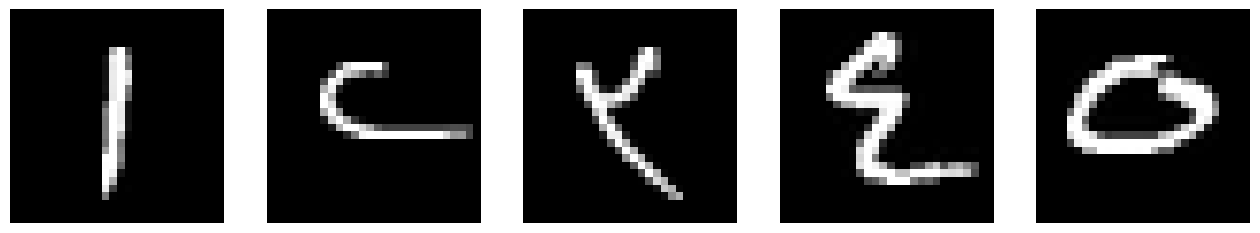

In [5]:
plt.figure(figsize=(16,10))                   
for i in range(5):
    print(i)
    plt.subplot(1,5,i+1)                                
    plt.imshow(img_data[i].reshape(28,28).T,cmap="gray")   
    plt.axis("off")                                    
plt.show()                                               

We plotted the first five images using using a grayscale colormap. These original images serve as the baseline we will compare the decoded images against when judging the autoencoder.  
Each image shows a light digit stroke on a dark background, roughly centred in the frame. Most pixels, especially around the edges, are 0 (black) and carry no information about the digit.  
Much of each image is "empty" space, which suggests the images can be compressed substantially without losing the digit itself.

### Reshape for Data Encoding

In [6]:
img_data = img_data.reshape((-1,28**2))
print("Shape of Array:",img_data.shape)
print("Shape of Each Row:",img_data[0].shape)

Shape of Array: (9998, 784)
Shape of Each Row: (784,)


We flattened each 28×28 image back into a one-dimensional array of 784 values. Keras `Dense` layers take one-dimensional input, so the autoencoder's input layer expects 784 values per image.  
The data shape is back to **(9998, 784)**, with values between 0 and 1, which is ready to feed into the network. 

## Clustering Section

In [7]:
import inspect                                    
import time                                       
from sklearn.decomposition import PCA             
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN   
from sklearn.metrics import silhouette_score    
from sklearn.neighbors import NearestNeighbors    
from sklearn.manifold import TSNE                
import matplotlib.patheffects as pe               

np.random.seed(0)                                

#### Reduce the data with PCA (n_components = 40)

In [8]:
model_pca = PCA(n_components=40, random_state=0)
img_pca = model_pca.fit_transform(img_data)
print("Shape before PCA:", img_data.shape) 
print("Shape after PCA: ", img_pca.shape)          
print("Share of total variance kept by 40 components:"f"{model_pca.explained_variance_ratio_.sum():.3f}")   

Shape before PCA: (9998, 784)
Shape after PCA:  (9998, 40)
Share of total variance kept by 40 components:0.765


Components needed for 70% of variance: 29
Components needed for 80% of variance: 49
Components needed for 90% of variance: 99
Components needed for 95% of variance: 167


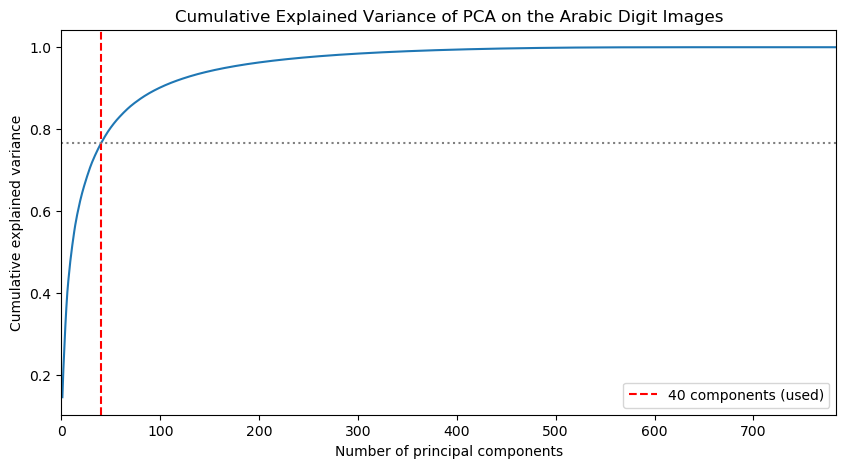

In [9]:
pca_full = PCA(random_state=0).fit(img_data)                  
cum_var = np.cumsum(pca_full.explained_variance_ratio_)       

for target in [0.70, 0.80, 0.90, 0.95]:                       
    n_needed = np.argmax(cum_var >= target) + 1               
    print(f"Components needed for {target:.0%} of variance: {n_needed}")

plt.figure(figsize=(10, 5)) 
plt.plot(np.arange(1, len(cum_var) + 1), cum_var)             
plt.axvline(40, color='red', linestyle='--', label='40 components (used)') 
plt.axhline(cum_var[39], color='grey', linestyle=':')
plt.xlim(0, 784)                                     
plt.xlabel('Number of principal components')         
plt.ylabel('Cumulative explained variance')          
plt.title('Cumulative Explained Variance of PCA on the Arabic Digit Images') 
plt.legend()                                                 
plt.show()                                             

#### Reconstruct the images with PCA

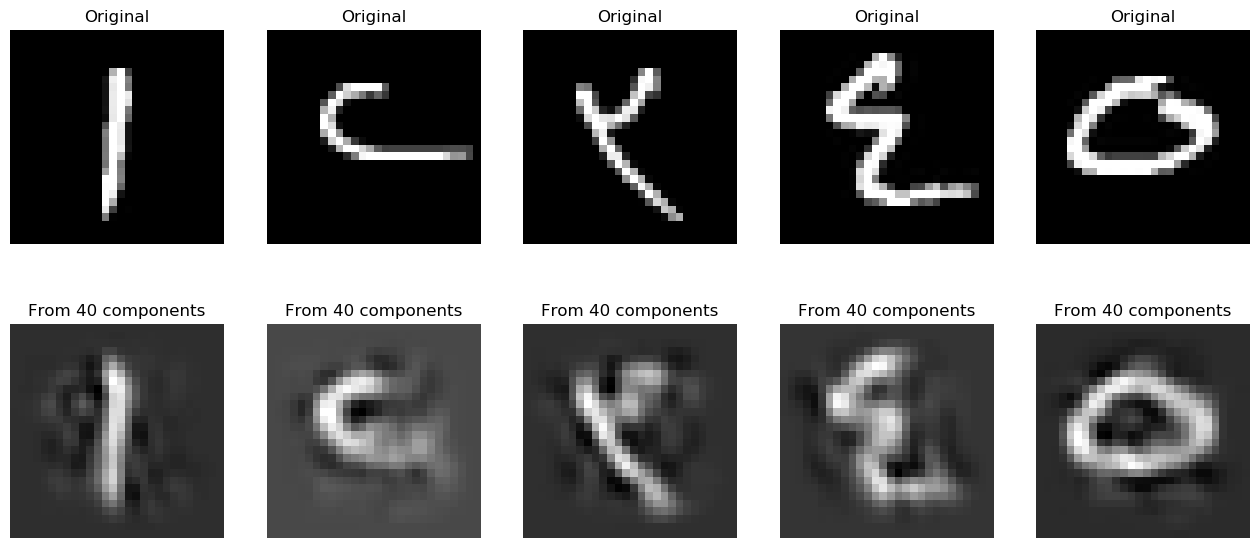

In [10]:
img_recon = model_pca.inverse_transform(img_pca)              

plt.figure(figsize=(16, 7))                                   
for i in range(5):                                            
    plt.subplot(2, 5, i + 1)                                  
    plt.imshow(img_data[i].reshape(28, 28).T, cmap='gray')
    plt.title('Original'); plt.axis('off')                    
    plt.subplot(2, 5, i + 6)                                  
    plt.imshow(img_recon[i].reshape(28, 28).T, cmap='gray')   
    plt.title('From 40 components'); plt.axis('off')          
plt.show()                                              

**PCA results**

We used PCA to shrink each image from 784 values down to 40. The 40 components keep about **76.5%** of the total variance in the data. The variance curve shows that keeping more components gives smaller and smaller gains. For example, it would take 49 components to reach 80% and 167 to reach 95%.

In the reconstructed images, every digit is still easy to recognise from just 40 numbers. Only some fine detail around the edges of the strokes is lost. This tells us that 40 components keep the shape of the digit, which is the part that matters for clustering.

### Models

We tried 13 models in total: 4 K-Means, 3 hierarchical and 6 DBSCAN. To score each model the same way, we wrote a helper function called `evaluate`. It fits the model, calculates the silhouette score and saves the results to a table.

We also recorded two extra things for each model, because the silhouette score on its own can be misleading:
- **Noise %**: DBSCAN can throw points away as "noise", and the silhouette score is only calculated on the points it keeps.
- **Largest cluster %**: if one cluster holds most of the images, the model is not really separating the digits.

In [ ]:
results = []         
cluster_labels = {}  
modeling_results = dict()

def evaluate(name, model, params):
    start = time.time()                                   
    labels = model.fit_predict(img_pca)                   
    seconds = time.time() - start                        
    clustered = labels != -1                              
    n_clusters = len(np.unique(labels[clustered]))
    noise_pct = 100 * (~clustered).mean()

    if n_clusters > 1:                                    
        sil = silhouette_score(img_pca[clustered], labels[clustered])   
    else:
        sil = np.nan                                     

    sizes = np.bincount(labels[clustered]) if n_clusters > 0 else np.array([0])  
    largest_pct = 100 * sizes.max() / len(labels)        

    model_results = {'Model': name,
                    'Hyperparameters': params,
                    'Clusters': n_clusters,
                    'Noise %': round(noise_pct, 1),
                    'Largest cluster %': round(largest_pct, 1),
                    'Silhouette': round(sil, 3),
                    'Fit time (s)': round(seconds, 1),
                    "Labels": labels,}
    results.append(model_results)
    cluster_labels[name] = labels
    print(f"{name:<28} clusters={n_clusters:<3} noise={noise_pct:5.1f}% "f"largest={largest_pct:5.1f}%  silhouette={sil:.3f}")
    return model_results

def plot_silhouette(metrics):
    # Plot Silhouette vs Cluster
    model_num = metrics["Model"]
    model_type = metrics["Hyperarameters"]
    k = int(metrics["Clusters"])
    labels = metrics["Labels"]
    silhouette_avg = metrics["Silhouette Score"]
    silhouette_values = metrics["Silhouette Coefficients"]

    prev_cluster_size = 0
    silhouette_plot, axis = plt.subplots(figsize=(8,6))
    for i in range(0,k):
        tick_loc = []
        for n in range(0,k):
            nth_cluster_values = silhouette_values[labels==n]
            nth_cluster_values.sort()
            nth_cluster_size = len(nth_cluster_values)
            tick_loc.append(nth_cluster_size/2+prev_cluster_size)
            y_upper_bounds = prev_cluster_size + nth_cluster_size
            axis.fill_betweenx(np.arange(prev_cluster_size,y_upper_bounds),0,nth_cluster_values)
            prev_cluster_size += nth_cluster_size
        axis.set_yticks(tick_loc)
        axis.set_yticklabels(np.arange(0,k), fontsize=8)
        axis.axvline(silhouette_avg,c=(36/255.0, 9/255.0, 82/255.0),linestyle="--")
        axis .set_title(f"Silhouette Scores for Iteration {model_num} (Hyperparameters: {model_type}, Clusters: {k})")
        axis.set_ylabel("Cluster")
        axis.set_xlabel("Silhouette Coefficient")
        plt.show()

#### K- Means 

In [12]:
i = 0
for k in [8, 10, 12, 15]:                                           
    km = KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=0)                                    
    modeling_results[i] = evaluate(f'K-Means (k={k})', km, f'n_clusters={k}, n_init=10')
    i += 1

K-Means (k=8)                clusters=8   noise=  0.0% largest= 22.7%  silhouette=0.116
K-Means (k=10)               clusters=10  noise=  0.0% largest= 21.0%  silhouette=0.122
K-Means (k=12)               clusters=12  noise=  0.0% largest= 12.9%  silhouette=0.132
K-Means (k=15)               clusters=15  noise=  0.0% largest= 11.6%  silhouette=0.133


We tried K-Means with 8, 10, 12 and 15 clusters. We started with 10 because there are 10 digits, and tried the others to see whether fewer or more clusters fit the data better. All four models used k-means++ to pick the starting centres and n_init = 10, which runs the model 10 times and keeps the best result.

The silhouette score went up slowly as we added clusters, from 0.116 (k = 8) to 0.133 (k = 15). The k = 10 model had a largest cluster holding 21% of the images.

#### Hierachical Clustering

In [13]:
for link in ['ward', 'complete', 'average']:                  
    agg = AgglomerativeClustering(n_clusters=10,linkage=link)
    modeling_results[i] = evaluate(f'Hierarchical ({link})', agg, f'n_clusters=10, linkage={link}')
    i += 1

Hierarchical (ward)          clusters=10  noise=  0.0% largest= 19.3%  silhouette=0.109
Hierarchical (complete)      clusters=10  noise=  0.0% largest= 42.5%  silhouette=0.088
Hierarchical (average)       clusters=10  noise=  0.0% largest= 81.0%  silhouette=0.140


Average linkage got the highest score (0.140), but it put 81% of the images into one giant cluster. Complete linkage put 42.5% into one cluster. Ward was the only one with balanced clusters (largest 19.3%), even though its score was lower (0.109).

#### DBSCAN 

In [14]:
for eps in [2.5, 3.0, 3.5]:                                    
    for min_samples in [10, 20]:          
        db = DBSCAN(eps=eps, min_samples=min_samples)
        modeling_results[i] = evaluate(f'DBSCAN (eps={eps}, min={min_samples})', db,f'eps={eps}, min_samples={min_samples}')
        i += 1

DBSCAN (eps=2.5, min=10)     clusters=20  noise= 58.6% largest= 37.3%  silhouette=-0.094
DBSCAN (eps=2.5, min=20)     clusters=10  noise= 73.8% largest= 22.6%  silhouette=-0.013
DBSCAN (eps=3.0, min=10)     clusters=13  noise= 31.8% largest= 64.9%  silhouette=-0.010
DBSCAN (eps=3.0, min=20)     clusters=4   noise= 45.4% largest= 50.5%  silhouette=0.179
DBSCAN (eps=3.5, min=10)     clusters=1   noise= 14.9% largest= 85.1%  silhouette=nan
DBSCAN (eps=3.5, min=20)     clusters=3   noise= 23.2% largest= 73.5%  silhouette=0.316


DBSCAN did not work well on this data. With a small eps, it marked most of the images as noise (up to 73.8%). With a larger eps, it merged almost everything into one cluster (up to 85.1%). None of the six models found anything close to 10 clear clusters. We think this is because the digits do not all have the same density, so no single eps value fits all of them.

#### Results 

In [15]:
results_df = pd.DataFrame(results)                            
results_df                                                  

,Clusters,Fit time (s),Hyperparameters,Labels,Largest cluster %,Model,Noise %,Silhouette
0,8,0.5,"n_clusters=8, n_init=10","[1, 6, 6, 6, 0, 1, 4, 7, 3, 4, 6, 5, 5, 1, 0, ...",22.7,K-Means (k=8),0.0,0.116
1,10,0.6,"n_clusters=10, n_init=10","[3, 6, 4, 4, 0, 3, 9, 5, 7, 8, 4, 6, 6, 3, 0, ...",21.0,K-Means (k=10),0.0,0.122
2,12,0.6,"n_clusters=12, n_init=10","[1, 10, 2, 11, 5, 1, 0, 7, 6, 3, 1, 4, 2, 11, ...",12.9,K-Means (k=12),0.0,0.132
3,15,0.9,"n_clusters=15, n_init=10","[1, 7, 6, 12, 10, 1, 4, 11, 3, 2, 1, 5, 6, 12,...",11.6,K-Means (k=15),0.0,0.133
4,10,2.9,"n_clusters=10, linkage=ward","[7, 3, 3, 9, 2, 1, 6, 5, 1, 0, 7, 4, 3, 9, 2, ...",19.3,Hierarchical (ward),0.0,0.109
5,10,3.1,"n_clusters=10, linkage=complete","[7, 7, 0, 7, 4, 7, 0, 9, 7, 1, 7, 0, 0, 7, 4, ...",42.5,Hierarchical (complete),0.0,0.088
6,10,2.7,"n_clusters=10, linkage=average","[5, 5, 5, 5, 8, 5, 5, 5, 5, 9, 5, 5, 5, 5, 8, ...",81.0,Hierarchical (average),0.0,0.140
7,20,2.8,"eps=2.5, min_samples=10","[0, 0, -1, -1, -1, 0, -1, -1, 0, -1, 0, -1, -1...",37.3,"DBSCAN (eps=2.5, min=10)",58.6,-0.094
8,10,2.6,"eps=2.5, min_samples=20","[0, -1, -1, -1, -1, 0, -1, -1, 6, -1, 0, -1, -...",22.6,"DBSCAN (eps=2.5, min=20)",73.8,-0.013
9,13,3.3,"eps=3.0, min_samples=10","[0, 0, 0, -1, -1, 0, 0, 0, 0, 1, 0, 0, 0, 0, -...",64.9,"DBSCAN (eps=3.0, min=10)",31.8,-0.010


The table shows all 13 models sorted by silhouette score. All of the scores are fairly low, with no model above 0.32. This is normal for handwritten digits, because everyone writes a little differently, so the clusters are never perfectly tight. Because of this, we did not just pick the model with the highest score. We also looked at the noise and largest-cluster columns.

#### Best Model choice 

In [16]:
digit_check = (df_clean.index.values + 1) % 10

for name in ['K-Means (k=10)', 'K-Means (k=12)']:
    print(name)
    display(pd.crosstab(cluster_labels[name], digit_check, rownames=['Cluster'], colnames=['Digit']))

K-Means (k=10)


Digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,3,0,13,1,2,824,0,5,4,1
1,418,0,1,0,2,11,0,0,0,0
2,68,7,45,28,12,35,412,19,107,519
3,19,946,11,10,56,0,24,0,1,13
4,24,28,185,691,913,31,29,95,61,41
5,2,0,9,3,7,43,0,0,761,3
6,0,0,736,10,4,15,0,0,1,6
7,65,18,0,15,4,2,535,7,65,417
8,398,0,0,0,0,14,0,0,0,0


K-Means (k=12)


Digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,1,0,0,45,0,22,0,847,0,0
1,24,938,17,26,52,0,31,1,3,28
2,18,2,168,863,47,21,10,101,43,17
3,346,0,1,0,0,4,0,0,1,0
4,0,0,700,7,3,14,0,0,1,4
5,3,0,14,1,2,817,0,5,4,1
6,7,4,2,11,5,2,546,8,71,422
7,2,0,3,0,6,37,0,0,728,3
8,215,0,0,0,2,1,0,0,1,2


We decided to check what digits are within each cluster starting K-Means with k = 10, since there are 10 digits. When we checked its clusters, we found that it put most of the 3s and 4s together into one cluster, which is why its largest cluster was so big. It also put a lot of 3s in with the 7s and split the 0s across two clusters.

Then we went back and tried k = 12. With 12 clusters, the 3s and 4s each get their own cluster, and so do the 1s, 2s, 5s, 7s and 8s. The two extra clusters went to digit 0. Since 0 in Arabic is written as a dot, people draw it at very different sizes, so K-Means split it into small, medium and large dots. The one problem k = 12 could not fix was 6 and 9, which are still mixed together across two clusters.

Before picking a final model, we took the two best models from each clustering type and compared them.

**K-Means:** The two best K-Means models were k = 12 (silhouette 0.132) and k = 15 (silhouette 0.133). Their scores are almost the same, and both have balanced clusters, with no cluster holding more than about 13% of the images. k = 15 is only 0.001 higher, but it splits the digits into even more pieces than we need. k = 12 already gives the separate digits their own clusters, so adding more clusters does not help. We did not choose k = 10 because, as shown above, it merged the 3s and 4s.

**Hierarchical:** The two best hierarchical models were average linkage (0.140) and ward linkage (0.109). Average linkage has the higher score, but it put 81% of all the images into one cluster, so it is not really separating the digits. Ward has a lower score but much more balanced clusters, so ward was the better of the two. However, all threee hierarchical models found 10 clusters each, which is in line with what was expected given there are 10 numbers.

**DBSCAN:** The two best DBSCAN models were eps = 3.5 with min_samples = 20 (0.316) and eps = 3.0 with min_samples = 20 (0.179). These have the highest scores in the whole table, but they are misleading. The first found only 3 clusters, threw out 23.2% of the images as noise and put 73.5% into one cluster. The second found only 4 clusters and threw out 45.4% as noise. Their scores are only high because the silhouette score ignores the points they threw away.

Before we make our final choice, we will be visualizing all the models that produced 10 clusters through t-SNE to gain a clearer picture of how well the clustering performed.

Cluster 0: digit 7 (93% of 915 images)
Cluster 1: digit 1 (84% of 1120 images)
Cluster 2: digit 3 (67% of 1290 images)
Cluster 3: digit 0 (98% of 352 images)
Cluster 4: digit 2 (96% of 729 images)
Cluster 5: digit 5 (96% of 847 images)
Cluster 6: digit 6 (51% of 1078 images)
Cluster 7: digit 8 (93% of 779 images)
Cluster 8: digit 0 (97% of 221 images)
Cluster 9: digit 0 (97% of 363 images)
Cluster 10: digit 9 (40% of 1292 images)
Cluster 11: digit 4 (85% of 1012 images)


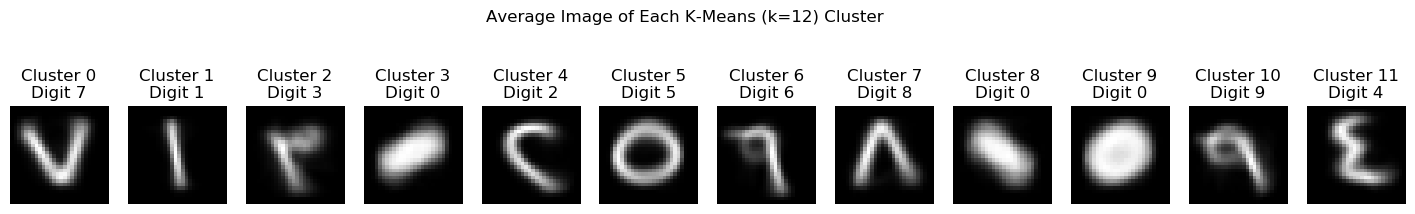

In [17]:
BEST = 'K-Means (k=12)'
best_labels = cluster_labels[BEST]
n_best = len(np.unique(best_labels))

cluster_to_digit = {}
for c in range(n_best):
    counts = np.bincount(digit_check[best_labels == c], minlength=10)
    cluster_to_digit[c] = counts.argmax()
    print(f"Cluster {c}: digit {counts.argmax()} ({counts.max() / counts.sum():.0%} of {counts.sum()} images)")

plt.figure(figsize=(18, 3))
for c in range(n_best):
    plt.subplot(1, n_best, c + 1)
    plt.imshow(img_data[best_labels == c].mean(axis=0).reshape(28, 28).T, cmap='gray')
    plt.title(f'Cluster {c}\nDigit {cluster_to_digit[c]}')
    plt.axis('off')
plt.suptitle(f'Average Image of Each {BEST} Cluster')
plt.show()

## T-SNE

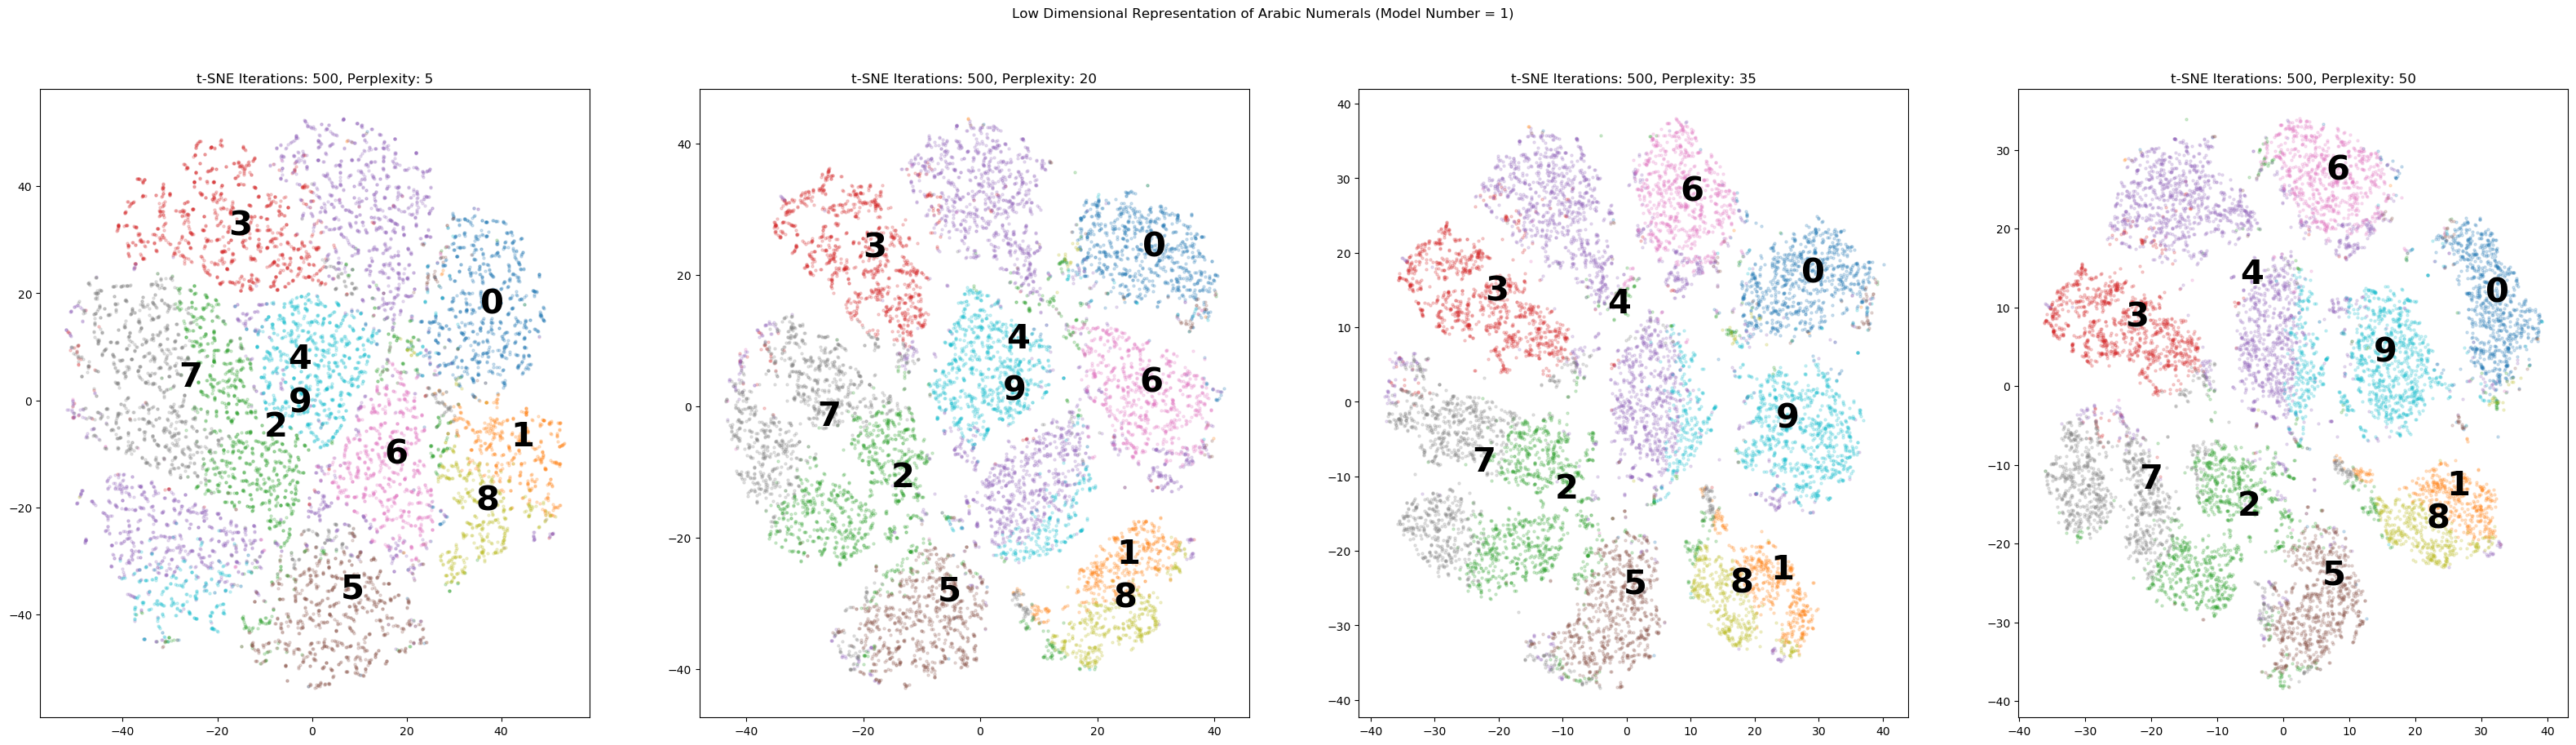

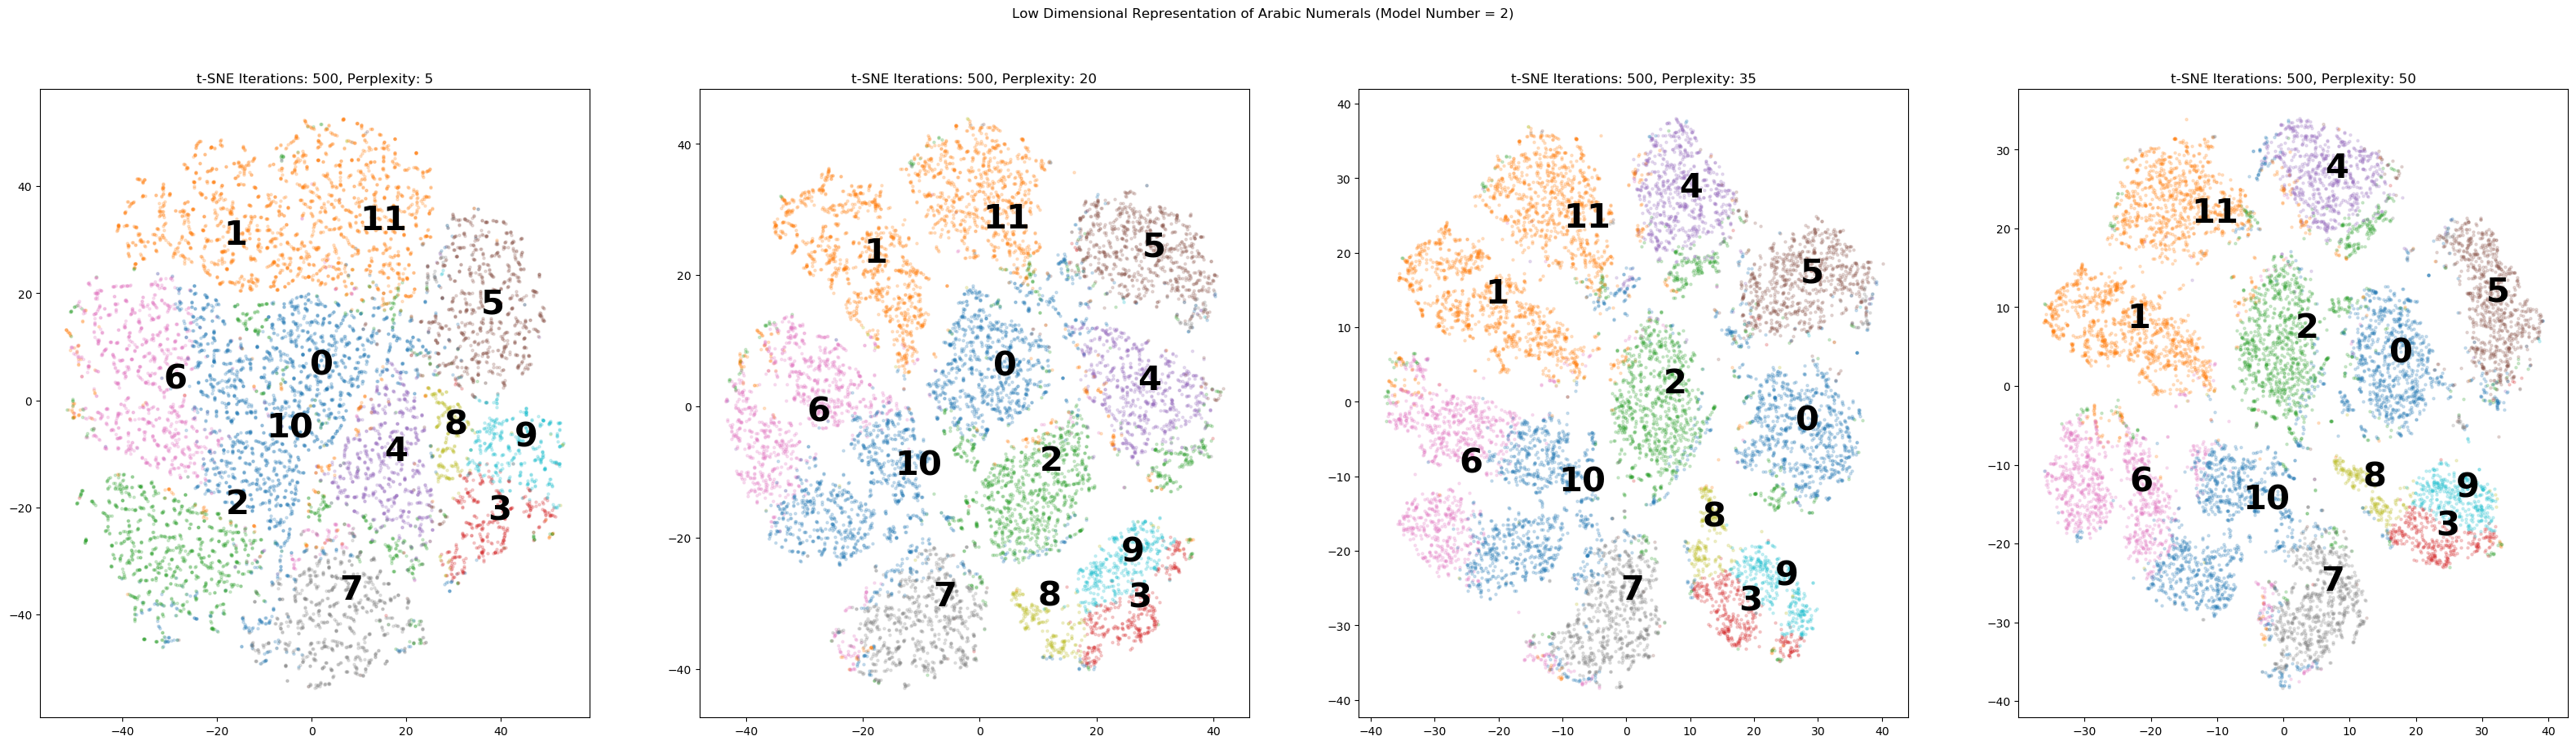

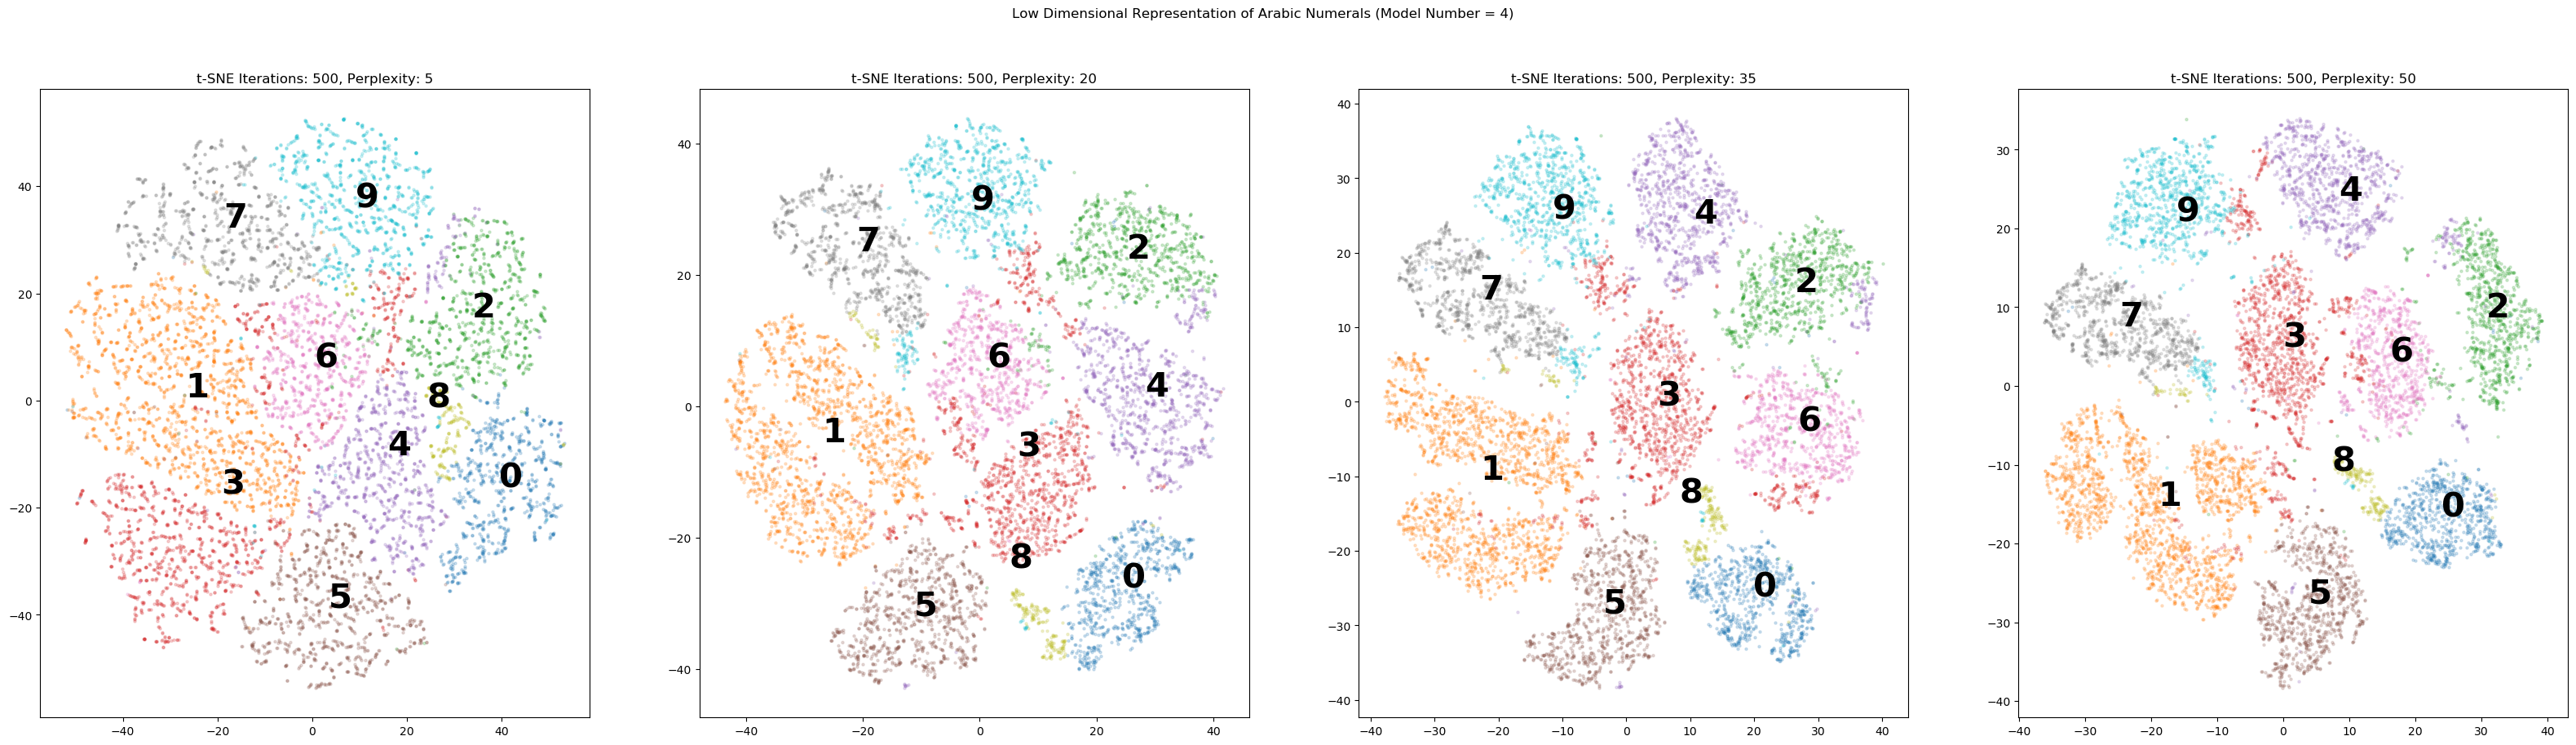

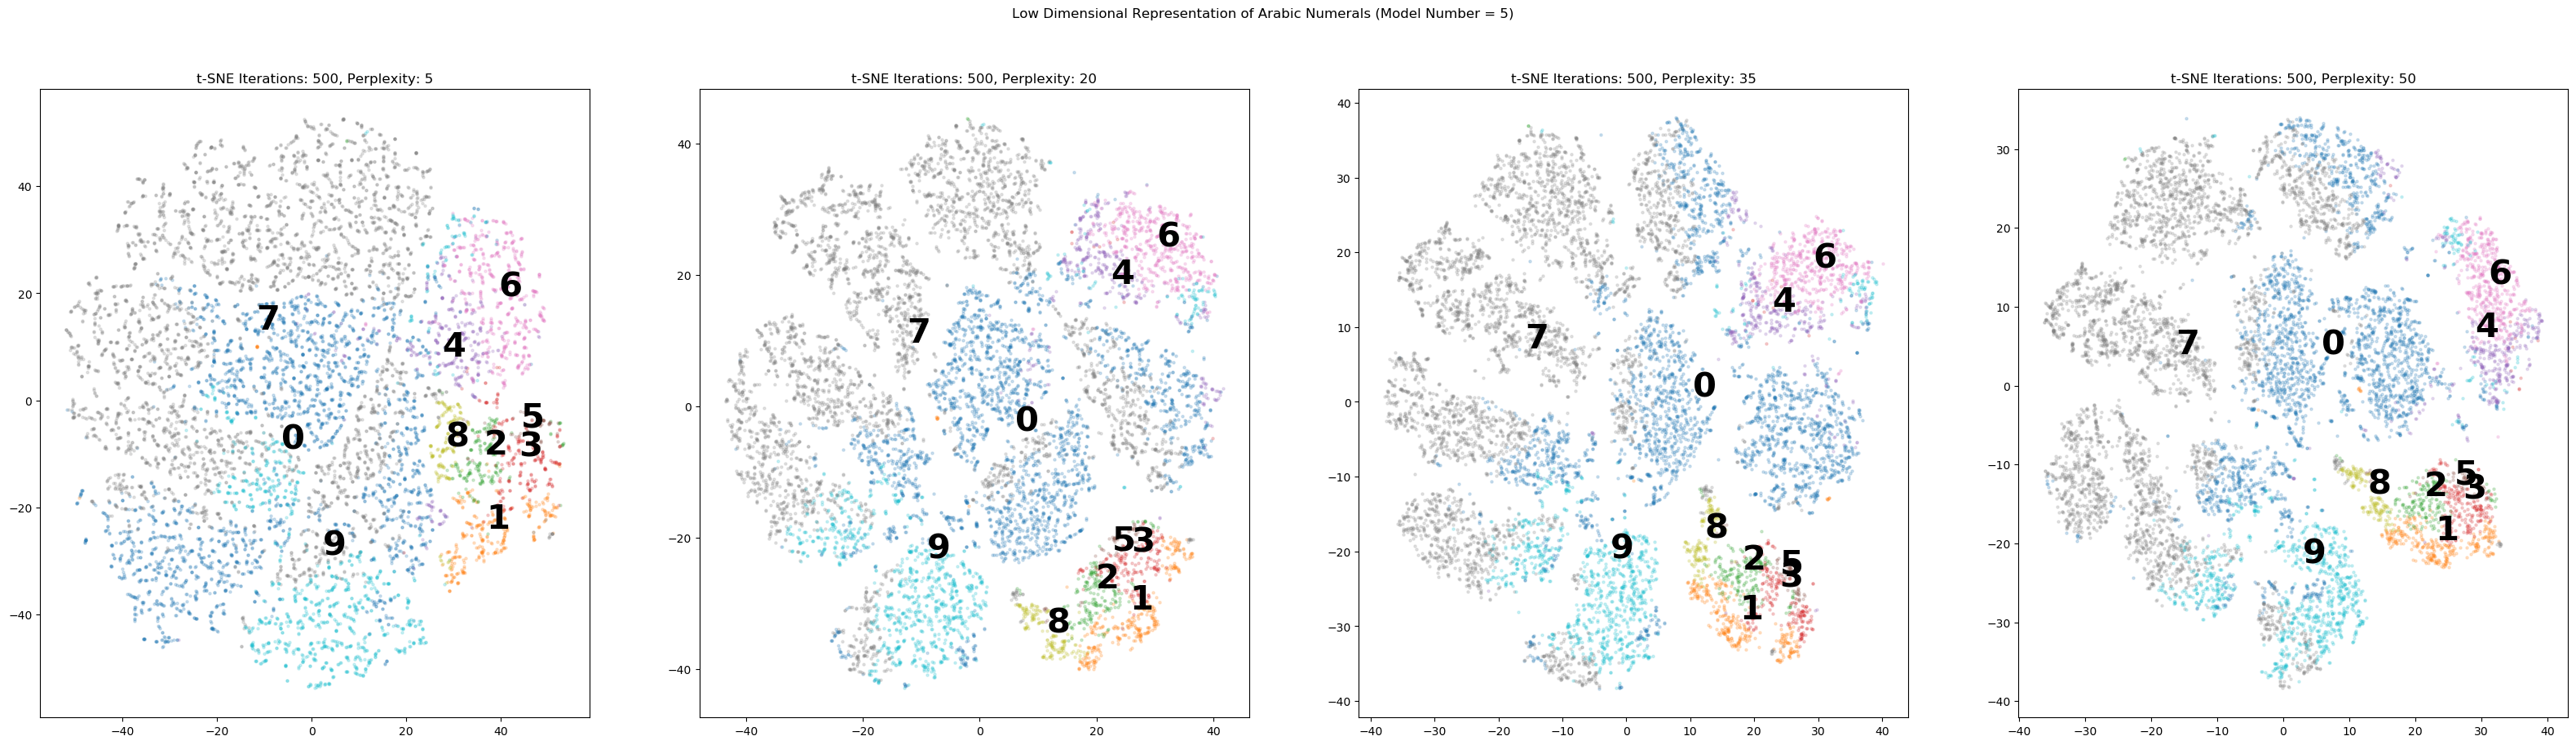

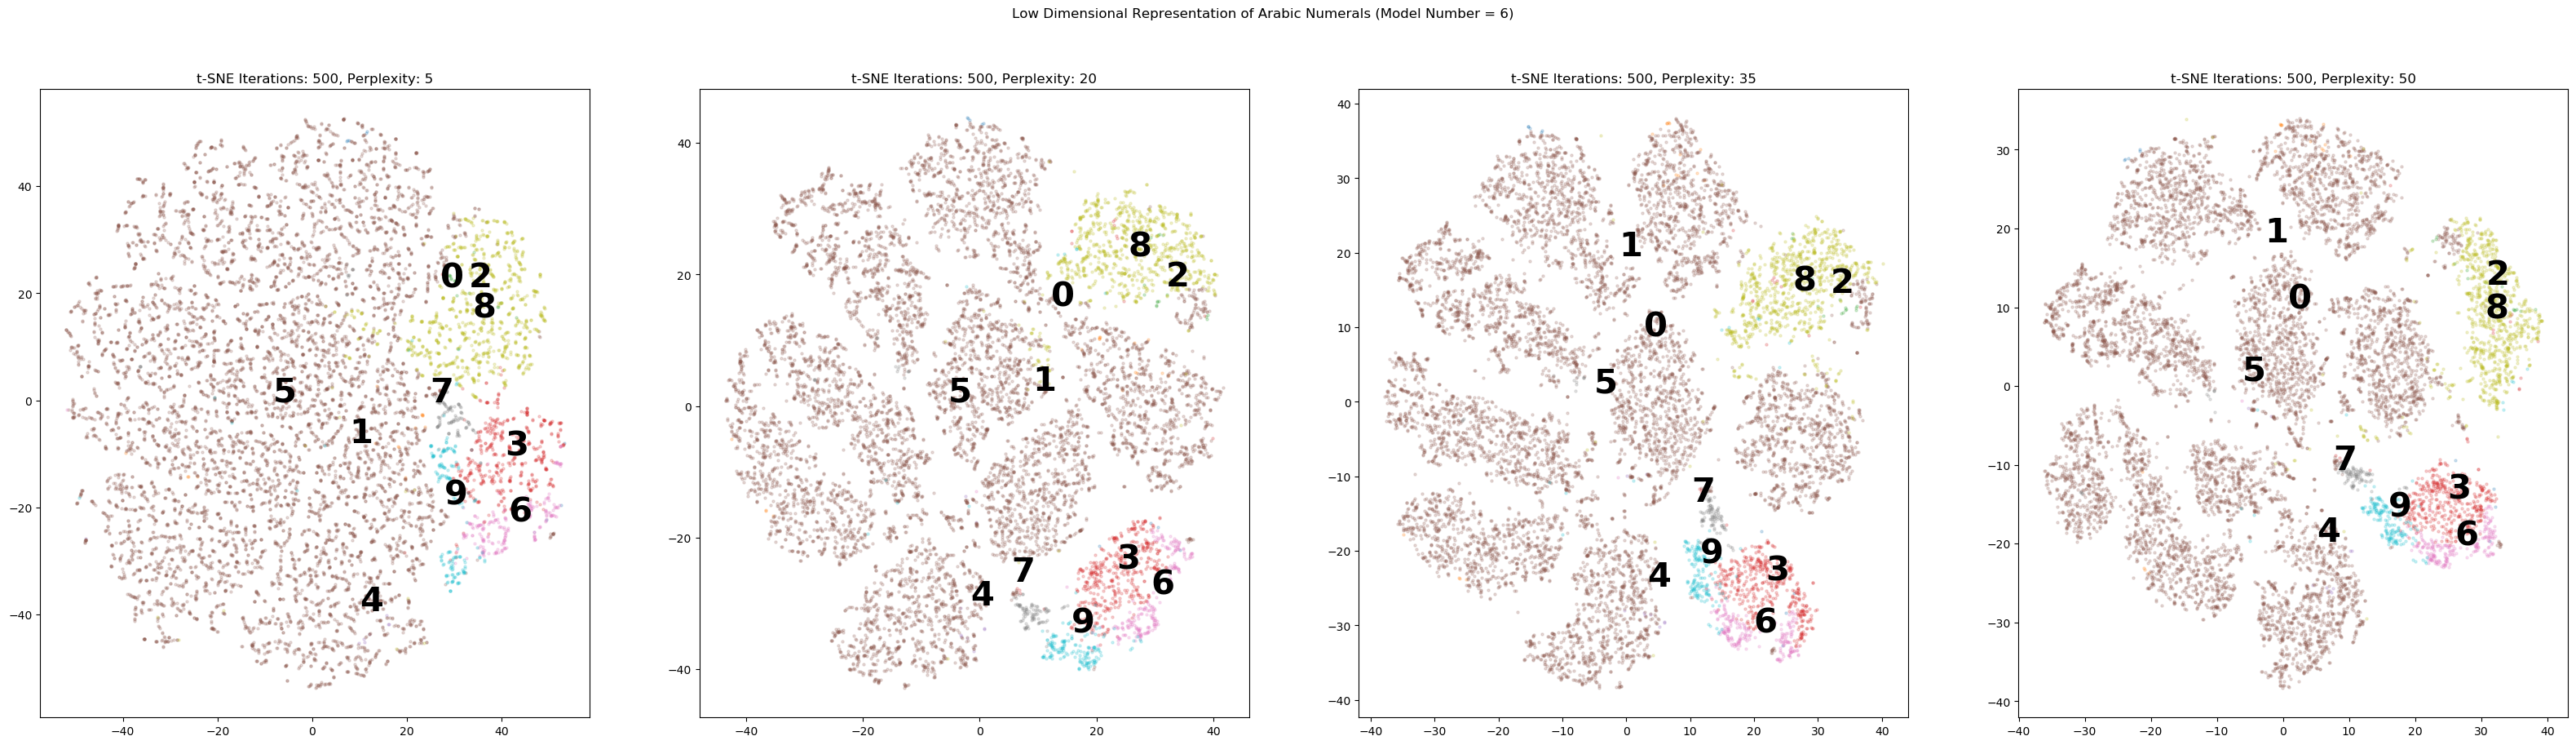

In [25]:
def label_data(data, model):
    labels = model["Labels"]
    # Add cluster labels to the features DataFrame
    df_labeled = data.copy()
    df_labeled["Cluster"] = labels
    return df_labeled

def plot_tsne(data_tsne, data_org, model):
    for c in range(model["Clusters"]):
        selections = data_tsne[data_org['Cluster'] == c].values
        plt.scatter(selections[:,0], selections[:,1], alpha=0.2, s=5)
        x, y = selections.mean(axis=0)
        plt.text(x, y, str(c), fontdict={'weight': 'bold', 'size': 30})
    if model["Model"].split()[0] == "DBSCAN":
        selections = data_tsne[data_org['Cluster'] == -1].values
        plt.scatter(selections[:,0], selections[:,1], alpha=0.2, s=5)
        plt.text(x, y, str(-1), fontdict={'weight': 'bold', 'size': 30})

low_dim_img = dict()
for j in [1,2,4,5,6]:
    pos = 1
    perplexity = range(5,55,15)
    tsne_iter = [500]
    height = len(tsne_iter)
    width = len(perplexity)
    plt.figure(figsize=(10*width, 10*height))
    for perp in perplexity:
        for iter in tsne_iter:
            t_sne = TSNE(perplexity=perp,n_iter=iter, random_state=0)
            img_labeled = label_data(pd.DataFrame(img_data),modeling_results[j])
            low_dim_img[j,(perp,iter)] = pd.DataFrame(t_sne.fit_transform(img_data))
            plt.suptitle(f'Low Dimensional Representation of Arabic Numerals (Model Number = {j})')
            plt.subplot(height,width,pos)
            plt.title(f"t-SNE Iterations: {iter}, Perplexity: {perp}")
            plot_tsne(low_dim_img[j,(perp,iter)], img_labeled, modeling_results[j])
            pos += 1
    plt.show()

For our final selected model, Model 5 and 6 produced very poor clustering results, with the majority of the images being assigned to only 1 or 2 clusters.  
Between model 1 and 2, they are both KMeans, however model 2 where k = 12 resulted in some of the visible groupings from t-SNE being divided into multiple small clusters.

For the above reasons, we decided to reject those models. This left us with only KMeans model 1 where k = 10 had a very hard time separating clusters 4 and 9. On the other hand, while model 4 had a couple issues on its own, it had much more clearly defined clusters overall.

In the end, we elected to proceed with Model 4 - Hierarchical Clustering.

In [21]:
results_df.iloc[4]

Clusters                                                            10
Fit time (s)                                                       2.9
Hyperparameters                            n_clusters=10, linkage=ward
Labels               [7, 3, 3, 9, 2, 1, 6, 5, 1, 0, 7, 4, 3, 9, 2, ...
Largest cluster %                                                 19.3
Model                                              Hierarchical (ward)
Noise %                                                              0
Silhouette                                                       0.109
Name: 4, dtype: object

## Conclusion

Our selected clustering model for the images uses `Hierarchical Clustering` with the hyperparameters of `n_clusters = 10`, `metric = euclidean`, and `linkage = ward`. Given that we are classifying images containing arabic numbers, we chose to set the clusters to 10 as that corresponds with the total number of digits.

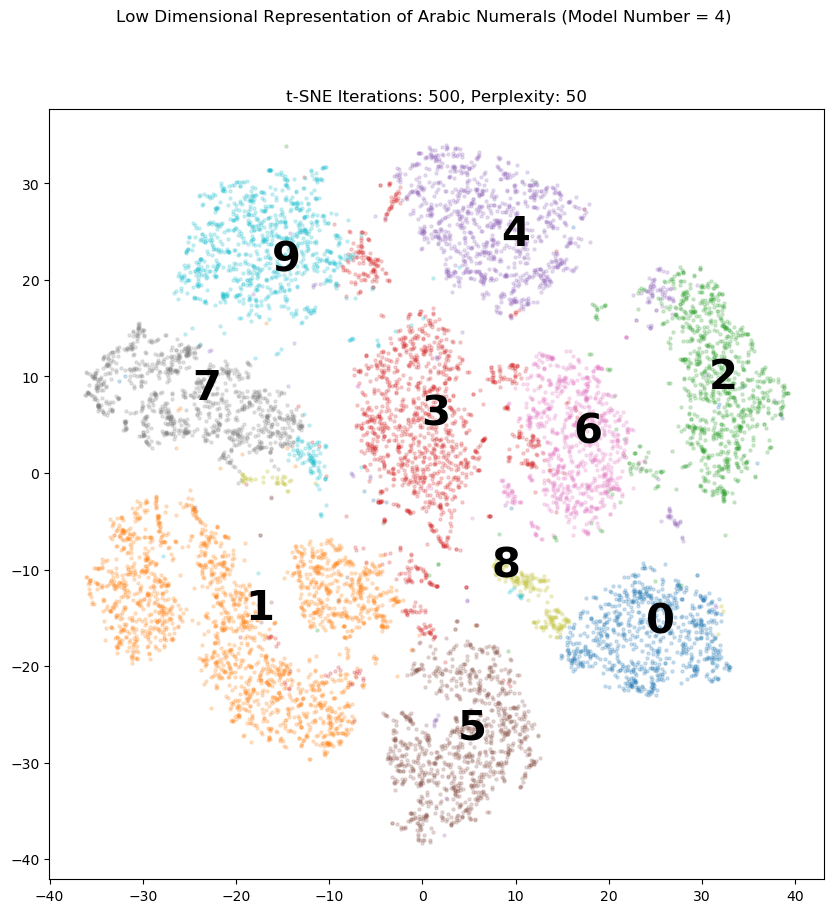

In [24]:
for j in [4]:
    pos = 1
    perplexity = [50]
    tsne_iter = [500]
    height = len(tsne_iter)
    width = len(perplexity)
    plt.figure(figsize=(10*width, 10*height))
    for perp in perplexity:
        for iter in tsne_iter:
            t_sne = TSNE(perplexity=perp,n_iter=iter, random_state=0)
            img_labeled = label_data(pd.DataFrame(img_data),modeling_results[j])
            low_dim_img[j,(perp,iter)] = pd.DataFrame(t_sne.fit_transform(img_data))
            plt.suptitle(f'Low Dimensional Representation of Arabic Numerals (Model Number = {j})')
            plt.subplot(height,width,pos)
            plt.title(f"t-SNE Iterations: {iter}, Perplexity: {perp}")
            plot_tsne(low_dim_img[j,(perp,iter)], img_labeled, modeling_results[j])
            pos += 1
    plt.show()

Based on the clustering performance as observed from the t-SNE visualization, this dataset appears to be relatively well stuited for classification. From our prior knowledge of the dataset, there are 10 distinct categories to be found, each corresponding to a unique arabic number. Therefore as long as the model is sufficiently trained and hyperparameters are finely tuned, the model should usually classify the image in the correct category.

There are a few clusters however that draw some concern. **Cluster 8** is extermely small compared to the rest. Additionally it is quite spread out, having small portions appearing as parts of other clusters in the t-SNE scatterplot. Some of the other clusters, such as 3, 9, and 4 appear to slightly bleed into their neighbours. While the majority of the images in these groups are very compact, there are some scattered in the edges of other clusters. Finally, cluster 1 is a source of concern. Unlike all the other groups, this cluster appears to be a collection of 3 different groupings. Although it's borders are quite well defined, there are two rivers of white space that cut through it splitting the cluster into 3 distinct sections. 

While there are a few concerning aspects to this clustering that may result in some digits being confused for others, as a whole this model had the best performance of those we tested, and we recommend going forward with this set of hyperparameters. 

Using PCA-reduced data can be better because it removes noise and repeated information, makes the distances between images more meaningful for clustering and t-SNE, and is much faster since each image has 40 values instead of 784. PCA works well when the features are related to each other, like neighbouring pixels, and a good way to check if it is appropriate is to rebuild the images from the components and see if they still look like the original digits, or to compare the results with and without PCA. To decide how many components to keep, you can pick enough to reach a target amount of variance, like 80%, 90% or 95%, and stop where adding more components barely helps. We used 40 components, which kept about 76.5% of the variance, and since the rebuilt images were still clear and the clustering still found clear groups, 40 components was enough for this task.

## Acknowledgement of Contributions
### Group 3 Members:  
Sebastian Levy  
Idongesit Orok  
Miracle Okojie  

### Task Distribution:  

Data Preprocessing - From Assignment 5  
PCA Dimensionality Reduction - Idongesit Orok  
Clustering Modeling - Idongesit Orok  
Clustering Model Analysis - Idongesit Orok  
t-SNE Visualizations - Sebastian Levy  
Final Model Selection - Sebastian Levy and Idongesit Orok  
Conclusion - Sebastian Levy and Idongesit Orok  

We, Group 3, acknowledge that we understand all parts of this assignment, including those which we did not personally carry out.